## 0. Setup

In [1]:
%pip install mlflow

  Using cached mlflow-3.17.2-py3-none-any.whl.metadata (50 kB)
  Using cached mlflow_skinny-3.17.2-py3-none-any.whl.metadata (51 kB)
Using cached mlflow-3.17.2-py3-none-any.whl (12.0 MB)
Using cached mlflow_skinny-3.17.2-py3-none-any.whl (4.1 MB)

   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 [mlflow-skinny]
   ---------------------------------------- 0/2 

In [3]:
# !pip install -q pandas numpy scikit-learn xgboost mlflow matplotlib seaborn joblib pyarrow
import os, json, time, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             mean_squared_error, mean_absolute_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor
import mlflow, mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

import emi_utils as eu          # shared cleaning + feature engineering

sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("models", exist_ok=True); os.makedirs("reports", exist_ok=True); os.makedirs("data", exist_ok=True)

In [4]:
# ------------------------- CONFIG -------------------------
DATA_PATH            = "emi_prediction_dataset.csv"
SAMPLE_N             = None      # e.g. 60_000 for a quick dry-run; None = use all rows
RANDOM_STATE         = 42
DROP_SALARY_OUTLIERS = True      # salary outside 15K-200K is corrupt (see audit) -> drop rows
MLFLOW_URI           = "sqlite:///mlflow.db"      # registry needs a DB backend
EXPERIMENT_CLF       = "EMI_Eligibility_Classification"
EXPERIMENT_REG       = "EMI_Max_Amount_Regression"
REG_CLF_NAME         = "EMI_Classifier"
REG_REG_NAME         = "EMI_Regressor"
EMI_MIN              = 500

## 1. Load data & quality audit

In [6]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", raw.shape)
raw.head()

Shape: (404800, 27)


,age,gender,marital_status,education,monthly_salary,employment_type,years_of_employment,company_type,house_type,monthly_rent,...,existing_loans,current_emi_amount,credit_score,bank_balance,emergency_fund,emi_scenario,requested_amount,requested_tenure,emi_eligibility,max_monthly_emi
0,38,Female,Married,Professional,82600.0,Private,0.9,Mid-size,Rented,20000.0,...,Yes,23700.0,660.0,303200.0,70200.0,Personal Loan EMI,850000.0,15,Not_Eligible,500.0
1,38,Female,Married,Graduate,21500.0,Private,7.0,MNC,Family,0.0,...,Yes,4100.0,714.0,92500.0,26900.0,E-commerce Shopping EMI,128000.0,19,Not_Eligible,700.0
2,38,Male,Married,Professional,86100.0,Private,5.8,Startup,Own,0.0,...,No,0.0,650.0,672100.0,324200.0,Education EMI,306000.0,16,Eligible,27775.0
3,58,Female,Married,High School,66800.0,Private,2.2,Mid-size,Own,0.0,...,No,0.0,685.0,440900.0,178100.0,Vehicle EMI,304000.0,83,Eligible,16170.0
4,48,Female,Married,Professional,57300.0,Private,3.4,Mid-size,Family,0.0,...,No,0.0,770.0,97300.0,28200.0,Home Appliances EMI,252000.0,7,Not_Eligible,500.0


In [7]:
# ---- data-quality audit on the RAW file (before touching anything) ----
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "n_unique": raw.nunique(),
})
display(audit[audit["missing"] > 0])

print("\nDuplicate rows:", raw.duplicated().sum())
print("\nGender spellings found :", sorted(raw["gender"].dropna().unique()))

# numeric columns stored as text, with malformed values like '58.0.0'
for c in ["age", "monthly_salary", "bank_balance"]:
    bad = raw[c].astype(str).str.count(r"\.") > 1
    print(f"{c:15s} malformed numbers (multiple dots): {bad.sum():5d}   e.g. {raw.loc[bad, c].head(2).tolist()}")

sal = pd.to_numeric(raw["monthly_salary"].astype(str).str.replace(r"^(-?\d+\.\d+)(\.\d+)+$", r"\1", regex=True), errors="coerce")
print(f"\nSalary outside 15K-200K : {((sal < 15000) | (sal > 200000)).sum():,}")
print(f"Credit score outside 300-850: {((raw.credit_score < 300) | (raw.credit_score > 850)).sum():,}")

,dtype,missing,missing_%,n_unique
education,object,2404,0.59,4
monthly_rent,float64,2426,0.60,4396
credit_score,float64,2420,0.60,427
bank_balance,object,2426,0.60,12261
emergency_fund,float64,2351,0.58,5486



Duplicate rows: 0

Gender spellings found : ['F', 'FEMALE', 'Female', 'M', 'MALE', 'Male', 'female', 'male']
age             malformed numbers (multiple dots):     3   e.g. ['58.0.0', '38.0.0']
monthly_salary  malformed numbers (multiple dots):  1993   e.g. ['64300.0.0', '23400.0.0.0']
bank_balance    malformed numbers (multiple dots):  1952   e.g. ['270700.0.0', '232900.0.0']

Salary outside 15K-200K : 10,065
Credit score outside 300-850: 4,776


### Cleaning rules (implemented in `emi_utils.clean_data`)
| Issue | Fix |
|---|---|
| Numbers stored as text / malformed (`58.0.0`) | strip extra `.0` suffixes → float |
| Gender typed 8 ways (`M`, `male`, `FEMALE` …) | map to `Male` / `Female` |
| Salary outside 15K–200K | **drop rows** (it drives the label; imputing would add label noise) |
| Credit score outside 300–850 | set to NaN → imputed later |
| Missing `monthly_rent` when not renting / `current_emi_amount` when no loans | fill 0 (logically correct) |
| Remaining NaNs (education, credit_score, bank_balance, emergency_fund …) | **median / mode imputation inside the sklearn pipeline, fit on train only** (no leakage) |

In [9]:
df = eu.clean_data(raw, drop_salary_outliers=DROP_SALARY_OUTLIERS)
if SAMPLE_N:
    df = df.sample(SAMPLE_N, random_state=RANDOM_STATE).reset_index(drop=True)
print("Working dataset:", df.shape)
print("\nRemaining missing values (handled by the pipeline imputer):")
print(df.isna().sum()[df.isna().sum() > 0])

# save a small clean sample for the Streamlit app's data-explorer / admin page
df.sample(min(25_000, len(df)), random_state=RANDOM_STATE).to_csv("data/sample_data.csv", index=False)

clean_data: 404,800 -> 394,735 rows | {'duplicates_removed': 0, 'age_out_of_range': 0, 'monthly_salary_out_of_range': 10065, 'credit_score_out_of_range': 4678}
Working dataset: (394735, 27)

Remaining missing values (handled by the pipeline imputer):
education         2328
monthly_rent       907
credit_score      7039
bank_balance      2381
emergency_fund    2283
dtype: int64


## 2. Exploratory Data Analysis

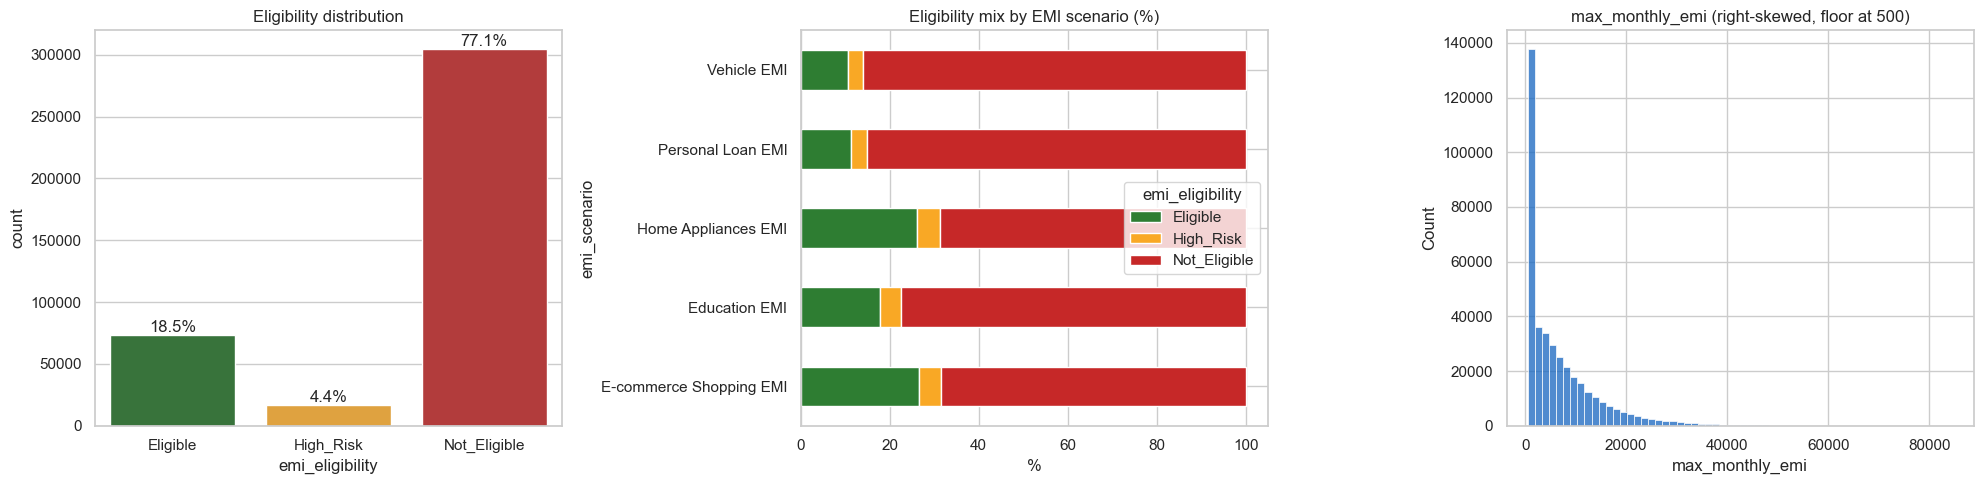

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
order = eu.CLASS_ORDER
sns.countplot(data=df, x="emi_eligibility", order=order, ax=ax[0], palette=["#2e7d32", "#f9a825", "#c62828"])
ax[0].set_title("Eligibility distribution")
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height()/len(df):.1%}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

ct = pd.crosstab(df["emi_scenario"], df["emi_eligibility"], normalize="index")[order] * 100
ct.plot(kind="barh", stacked=True, ax=ax[1], color=["#2e7d32", "#f9a825", "#c62828"])
ax[1].set_title("Eligibility mix by EMI scenario (%)"); ax[1].set_xlabel("%")

sns.histplot(df["max_monthly_emi"], bins=60, ax=ax[2], color="#1565c0")
ax[2].set_title("max_monthly_emi (right-skewed, floor at 500)")
plt.tight_layout(); plt.savefig("reports/eda_targets.png", dpi=110); plt.show()

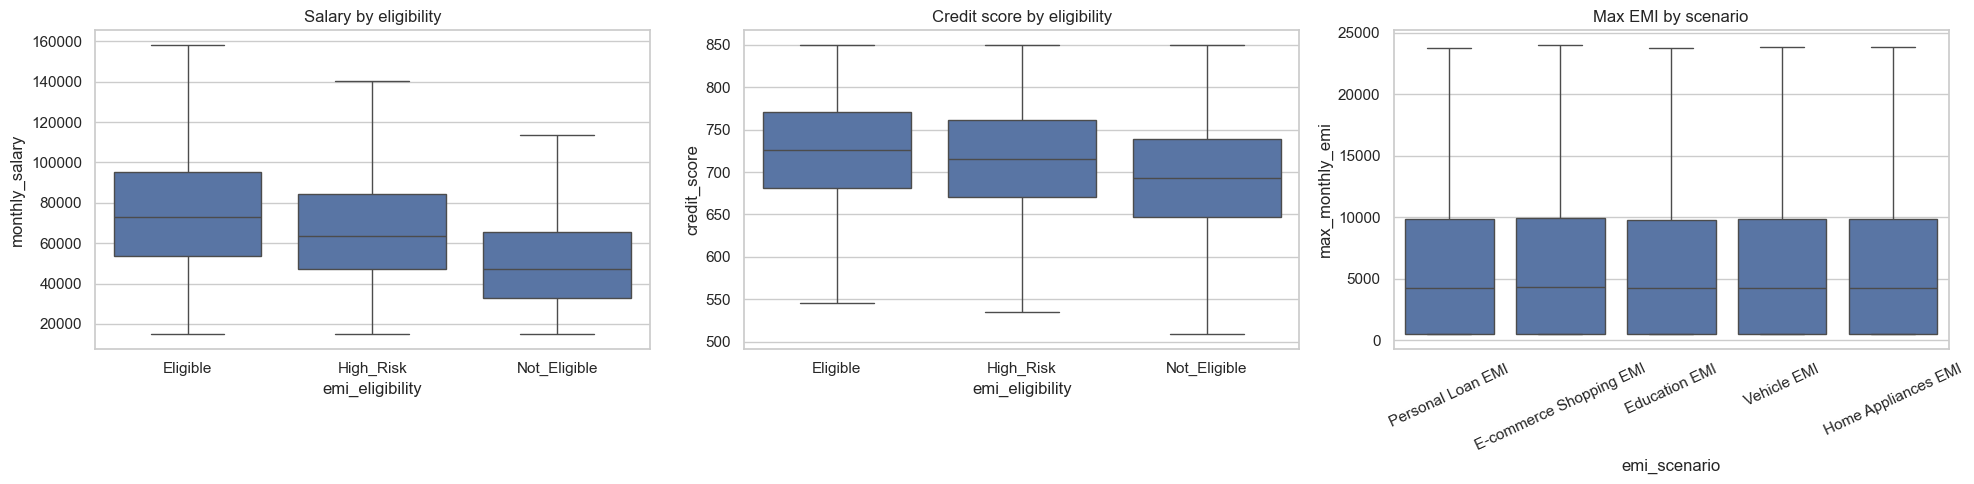

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.boxplot(data=df, x="emi_eligibility", y="monthly_salary", order=order, ax=ax[0], showfliers=False)
ax[0].set_title("Salary by eligibility")
sns.boxplot(data=df, x="emi_eligibility", y="credit_score", order=order, ax=ax[1], showfliers=False)
ax[1].set_title("Credit score by eligibility")
sns.boxplot(data=df, x="emi_scenario", y="max_monthly_emi", ax=ax[2], showfliers=False)
ax[2].tick_params(axis="x", rotation=25); ax[2].set_title("Max EMI by scenario")
plt.tight_layout(); plt.savefig("reports/eda_numeric_vs_target.png", dpi=110); plt.show()

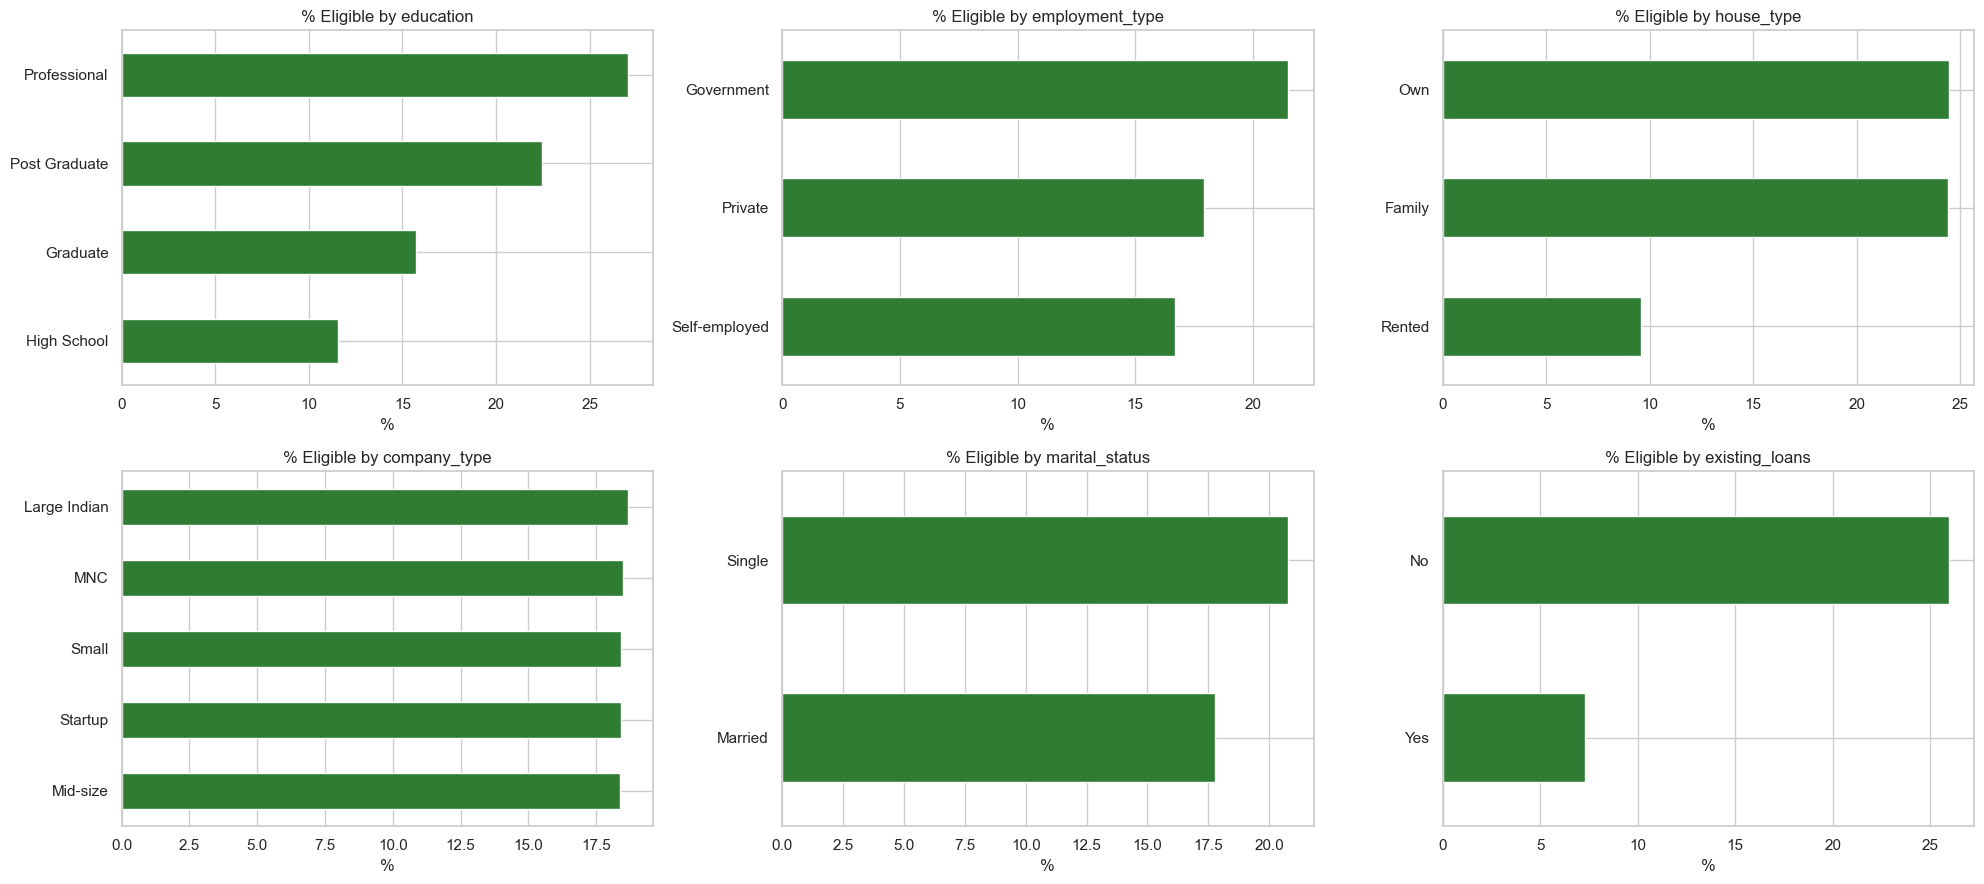

In [12]:
# demographic / risk-factor patterns: share of 'Eligible' applicants
fig, ax = plt.subplots(2, 3, figsize=(20, 9)); ax = ax.ravel()
for a, c in zip(ax, ["education", "employment_type", "house_type", "company_type", "marital_status", "existing_loans"]):
    (df.assign(elig=(df.emi_eligibility == "Eligible")).groupby(c)["elig"].mean() * 100).sort_values().plot(kind="barh", ax=a, color="#2e7d32")
    a.set_title(f"% Eligible by {c}"); a.set_xlabel("%"); a.set_ylabel("")
plt.tight_layout(); plt.savefig("reports/eda_demographics.png", dpi=110); plt.show()

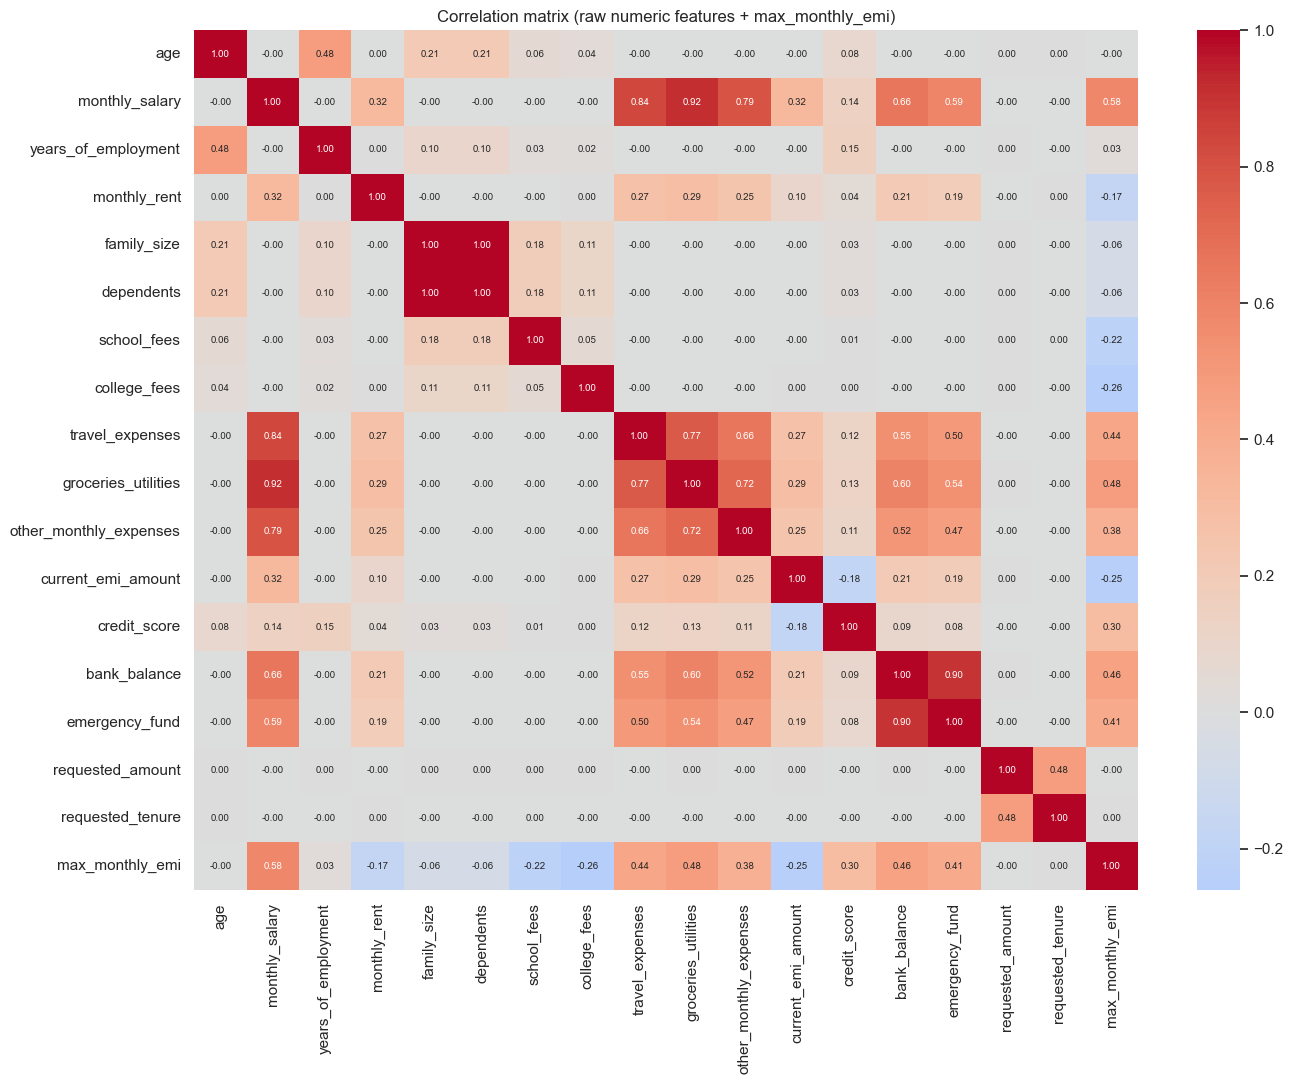

In [13]:
num_for_corr = eu.NUM_COLS + [eu.REG_TARGET]
plt.figure(figsize=(14, 11))
sns.heatmap(df[num_for_corr].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation matrix (raw numeric features + max_monthly_emi)")
plt.tight_layout(); plt.savefig("reports/eda_correlation.png", dpi=110); plt.show()

In [14]:
# ---- business insights, computed from the data ----
d = df.assign(elig=(df.emi_eligibility == "Eligible"), not_elig=(df.emi_eligibility == "Not_Eligible"))
d["credit_band"] = pd.cut(d.credit_score, [299, 579, 669, 739, 799, 850], labels=["Poor", "Fair", "Good", "Very Good", "Excellent"])
d["dti_band"] = pd.cut(d.current_emi_amount / d.monthly_salary, [-0.01, 0, 0.1, 0.2, 5], labels=["No EMI", "<10%", "10-20%", ">20%"])
print("Overall eligibility mix:\n", (df.emi_eligibility.value_counts(normalize=True) * 100).round(1).to_string())
print("\n% Eligible by credit band:\n",  (d.groupby("credit_band", observed=True).elig.mean() * 100).round(1).to_string())
print("\n% Eligible by existing-EMI burden:\n", (d.groupby("dti_band", observed=True).elig.mean() * 100).round(1).to_string())
print("\n% Not_Eligible by scenario:\n", (d.groupby("emi_scenario").not_elig.mean() * 100).round(1).to_string())
print("\nMedian max EMI (INR) by employment type:\n", d.groupby("employment_type").max_monthly_emi.median().round(0).to_string())

Overall eligibility mix:
 emi_eligibility
Not_Eligible    77.1
Eligible        18.5
High_Risk        4.4

% Eligible by credit band:
 credit_band
Poor          6.2
Fair         11.7
Good         18.2
Very Good    25.7
Excellent    31.9

% Eligible by existing-EMI burden:
 dti_band
No EMI    25.9
<10%       4.9
10-20%     9.2
>20%       5.4

% Not_Eligible by scenario:
 emi_scenario
E-commerce Shopping EMI    68.5
Education EMI              77.4
Home Appliances EMI        68.6
Personal Loan EMI          85.2
Vehicle EMI                86.1

Median max EMI (INR) by employment type:
 employment_type
Government       5040.0
Private          4144.0
Self-employed    3843.0


## 3. Feature engineering
`emi_utils.add_features` creates (all using safe division): `total_expenses`, `expense_to_income`, `debt_to_income`, `disposable_income`, `requested_emi_est` (amount ÷ tenure), `emi_to_income`, `affordability_ratio`, `loan_to_income`, `savings_ratio`, `emergency_months`, `employment_stability`, `dependents_per_member`, `income_per_member`, `credit_risk_score` (composite), `stress_ratio`, and the interaction `credit_x_dti`.
It sits **inside the sklearn pipeline** (`FunctionTransformer`), so the app applies identical logic at prediction time.

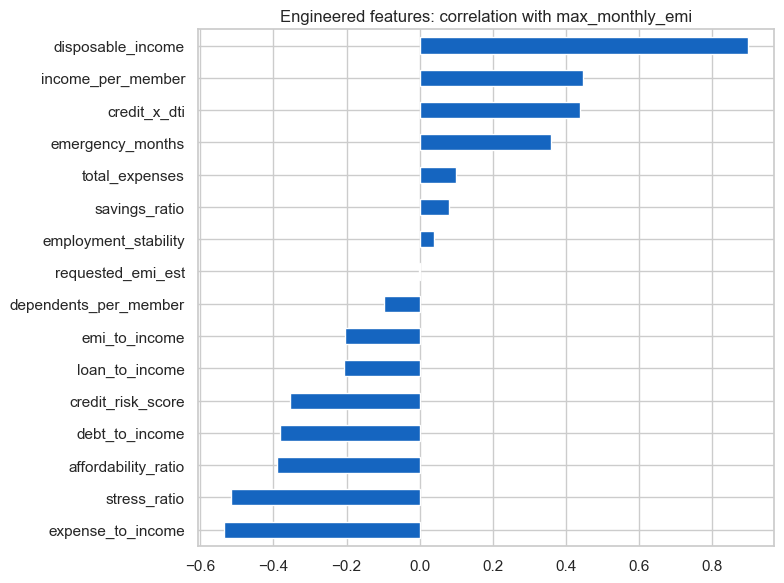

,count,mean,std,min,25%,50%,75%,max
total_expenses,394735.0,40252.074,20224.206,4100.000,25500.000,36900.000,51200.000,194400.000
expense_to_income,394735.0,0.748,0.296,0.250,0.533,0.700,0.882,3.738
debt_to_income,394735.0,0.080,0.105,0.000,0.000,0.000,0.175,0.321
disposable_income,394735.0,12383.864,18081.142,-54300.000,700.000,10700.000,22200.000,130300.000
requested_emi_est,394735.0,14755.926,13874.286,416.667,5705.882,10473.684,18823.529,124583.333
emi_to_income,394735.0,0.330,0.393,0.003,0.101,0.205,0.407,7.549
affordability_ratio,394735.0,4.833,8.597,0.006,0.411,1.182,4.974,50.000
loan_to_income,394735.0,0.692,0.818,0.005,0.184,0.396,0.883,8.306
savings_ratio,390085.0,0.496,0.257,0.050,0.275,0.492,0.709,1.083
emergency_months,392452.0,2.594,1.898,0.053,1.159,2.151,3.553,16.946


In [15]:
fe = eu.add_features(df[eu.RAW_FEATURES])
chk = pd.concat([fe[eu.ENGINEERED], df[eu.REG_TARGET]], axis=1).corr()[eu.REG_TARGET].drop(eu.REG_TARGET).sort_values()
plt.figure(figsize=(8, 6)); chk.plot(kind="barh", color="#1565c0")
plt.title("Engineered features: correlation with max_monthly_emi"); plt.tight_layout()
plt.savefig("reports/eda_engineered_corr.png", dpi=110); plt.show()
fe[eu.ENGINEERED].describe().T.round(3)

## 4. Train / validation / test split (70 / 15 / 15, stratified on eligibility)

In [16]:
X = df[eu.RAW_FEATURES]
y_clf = df[eu.CLF_TARGET].map({c: i for i, c in enumerate(eu.CLASS_ORDER)}).astype(int)
y_reg = df[eu.REG_TARGET]

X_tr, X_tmp, yc_tr, yc_tmp, yr_tr, yr_tmp = train_test_split(X, y_clf, y_reg, test_size=0.30, stratify=y_clf, random_state=RANDOM_STATE)
X_va, X_te, yc_va, yc_te, yr_va, yr_te = train_test_split(X_tmp, yc_tmp, yr_tmp, test_size=0.50, stratify=yc_tmp, random_state=RANDOM_STATE)
print(f"train {len(X_tr):,} | val {len(X_va):,} | test {len(X_te):,}")
print("class balance (train):", (yc_tr.value_counts(normalize=True).sort_index().round(3)).to_dict(), "->", eu.CLASS_ORDER)

train 276,314 | val 59,210 | test 59,211
class balance (train): {0: 0.185, 1: 0.044, 2: 0.771} -> ['Eligible', 'High_Risk', 'Not_Eligible']


### Preprocessing pipeline
* numeric → median impute → standardise
* categorical → mode impute → one-hot (unknown categories ignored)
* fitted on **train only**

In [17]:
extra = [c for c in eu.ENGINEERED]
num_cols = eu.NUM_COLS + extra
cat_cols = eu.CAT_COLS

ct = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
])
pre = Pipeline([("fe", FunctionTransformer(eu.add_features, validate=False)), ("ct", ct)])

Xtr_t = pre.fit_transform(X_tr); Xva_t = pre.transform(X_va); Xte_t = pre.transform(X_te)
feat_names = list(pre.named_steps["ct"].get_feature_names_out())
print("Transformed feature matrix:", Xtr_t.shape, "| NaNs left:", int(np.isnan(Xtr_t).sum()))

Transformed feature matrix: (276314, 59) | NaNs left: 0


## 5. MLflow setup
Tracking store = SQLite (`mlflow.db`), which also enables the **Model Registry**. View the dashboard with:
```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

In [18]:
mlflow.set_tracking_uri(MLFLOW_URI)
client = MlflowClient()

def _simple_params(model):
    return {k: v for k, v in model.get_params().items() if isinstance(v, (int, float, str, bool, type(None)))}

def clf_metrics(y, proba):
    pred = proba.argmax(1)
    return {"accuracy": accuracy_score(y, pred),
            "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y, pred, average="macro"),
            "f1_weighted": f1_score(y, pred, average="weighted"),
            "roc_auc_ovr": roc_auc_score(y, proba, multi_class="ovr", average="macro")}

def reg_metrics(y, p):
    p = np.maximum(p, EMI_MIN)
    return {"rmse": float(np.sqrt(mean_squared_error(y, p))), "mae": float(mean_absolute_error(y, p)),
            "r2": float(r2_score(y, p)), "mape": float(np.mean(np.abs((y - p) / y)) * 100)}

def log_common(model, name, task, fit_s, mv, mt):
    mlflow.set_tags({"task": task, "model_type": name})
    mlflow.log_params(_simple_params(model))
    mlflow.log_params({"n_train": len(X_tr), "n_features": Xtr_t.shape[1], "fit_seconds": round(fit_s, 1)})
    mlflow.log_metrics({f"val_{k}": v for k, v in mv.items()})
    mlflow.log_metrics({f"test_{k}": v for k, v in mt.items()})
    mlflow.log_artifact("emi_utils.py")

2026/10/27 14:35:36 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/27 14:35:36 INFO mlflow.store.db.utils: Updating database tables


## 6. Classification models — EMI eligibility
Class imbalance (~77 % Not_Eligible) is handled with balanced class/sample weights; **selection metric = validation macro-F1** (accuracy alone would reward ignoring the minority classes).

In [19]:
mlflow.set_experiment(EXPERIMENT_CLF)
w_tr = compute_sample_weight("balanced", yc_tr)

clf_models = {
    "LogisticRegression": (LogisticRegression(max_iter=300, C=1.0, class_weight="balanced"), {}),
    "DecisionTree":       (DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE), {}),
    "RandomForest":       (RandomForestClassifier(n_estimators=120, max_depth=16, min_samples_leaf=5, class_weight="balanced_subsample",
                                                  n_jobs=-1, random_state=RANDOM_STATE), {}),
    "XGBoost":            (XGBClassifier(n_estimators=500, learning_rate=0.08, max_depth=7, subsample=0.85, colsample_bytree=0.85,
                                         tree_method="hist", eval_metric="mlogloss", early_stopping_rounds=30,
                                         n_jobs=-1, random_state=RANDOM_STATE),
                           {"sample_weight": w_tr, "eval_set": [(Xva_t, yc_va)], "verbose": False}),
}

clf_results, clf_fitted, clf_versions, clf_runs = [], {}, {}, {}
for name, (model, fit_kw) in clf_models.items():
    with mlflow.start_run(run_name=name) as run:
        t0 = time.time(); model.fit(Xtr_t, yc_tr, **fit_kw); fit_s = time.time() - t0
        pv, pt = model.predict_proba(Xva_t), model.predict_proba(Xte_t)
        mv, mt = clf_metrics(yc_va, pv), clf_metrics(yc_te, pt)
        log_common(model, name, "classification", fit_s, mv, mt)

        # artifact: confusion matrix (test)
        fig, a = plt.subplots(figsize=(5.5, 5))
        ConfusionMatrixDisplay(confusion_matrix(yc_te, pt.argmax(1)), display_labels=eu.CLASS_ORDER).plot(ax=a, cmap="Blues", colorbar=False)
        a.set_title(f"{name} — test confusion matrix"); plt.tight_layout()
        mlflow.log_figure(fig, "confusion_matrix.png"); plt.close(fig)

        # full pipeline (preprocessing + model) -> registry
        pipe = Pipeline([("pre", pre), ("model", model)])
        info = mlflow.sklearn.log_model(pipe, name="model", signature=infer_signature(X_te.head(50), pipe.predict(X_te.head(50))),
                                        input_example=X_te.head(3), registered_model_name=REG_CLF_NAME, code_paths=["emi_utils.py"], serialization_format="cloudpickle")
        clf_versions[name] = getattr(info, "registered_model_version", None)
        clf_runs[name] = run.info.run_id
    clf_fitted[name] = model
    clf_results.append({"model": name, **{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()}, "fit_s": round(fit_s, 1)})
    print(f"{name:20s} val F1-macro={mv['f1_macro']:.4f}  test acc={mt['accuracy']:.4f}  AUC={mt['roc_auc_ovr']:.4f}  ({fit_s:.0f}s)")

clf_df = pd.DataFrame(clf_results).set_index("model")
clf_df.round(4)

2026/10/27 14:35:47 INFO mlflow.tracking.fluent: Experiment with name 'EMI_Eligibility_Classification' does not exist. Creating a new experiment.
2026/10/27 14:36:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully registered model 'EMI_Classifier'.
Created version '1' of model 'EMI_Classifier'.


LogisticRegression   val F1-macro=0.7822  test acc=0.9078  AUC=0.9846  (25s)


2026/10/27 14:37:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Registered model 'EMI_Classifier' already exists. Creating a new version of this model...
Created version '2' of model 'EMI_Classifier'.


...

RandomForest         val F1-macro=0.8229  test acc=0.9378  AUC=0.9900  (58s)


2026/10/27 14:40:28 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost              val F1-macro=0.9306  test acc=0.9806  AUC=0.9984  (119s)


Registered model 'EMI_Classifier' already exists. Creating a new version of this model...
Created version '4' of model 'EMI_Classifier'.


,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_f1_weighted,val_roc_auc_ovr,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted,test_roc_auc_ovr,fit_s
model,,,,,,,,,,,,,
LogisticRegression,0.9109,0.7644,0.8955,0.7822,0.9297,0.9842,0.9078,0.7633,0.8994,0.7801,0.9279,0.9846,24.8
DecisionTree,0.9503,0.8158,0.9287,0.8483,0.9574,0.9869,0.9478,0.8106,0.9262,0.8432,0.9556,0.9847,23.9
RandomForest,0.9385,0.7938,0.9094,0.8229,0.9484,0.9896,0.9378,0.7938,0.9137,0.8234,0.9480,0.9900,57.6
XGBoost,0.9815,0.9049,0.9654,0.9306,0.9825,0.9983,0.9806,0.9008,0.9661,0.9282,0.9818,0.9984,118.9


## 7. Regression models — maximum monthly EMI

In [20]:
mlflow.set_experiment(EXPERIMENT_REG)

reg_models = {
    "LinearRegression": (LinearRegression(), {}),
    "DecisionTree":     (DecisionTreeRegressor(max_depth=14, min_samples_leaf=20, random_state=RANDOM_STATE), {}),
    "RandomForest":     (RandomForestRegressor(n_estimators=120, max_depth=18, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE), {}),
    "XGBoost":          (XGBRegressor(n_estimators=800, learning_rate=0.06, max_depth=7, subsample=0.85, colsample_bytree=0.85,
                                      tree_method="hist", early_stopping_rounds=40, n_jobs=-1, random_state=RANDOM_STATE),
                         {"eval_set": [(Xva_t, yr_va)], "verbose": False}),
}

reg_results, reg_fitted, reg_versions, reg_runs = [], {}, {}, {}
for name, (model, fit_kw) in reg_models.items():
    with mlflow.start_run(run_name=name) as run:
        t0 = time.time(); model.fit(Xtr_t, yr_tr, **fit_kw); fit_s = time.time() - t0
        pv, pt = model.predict(Xva_t), model.predict(Xte_t)
        mv, mt = reg_metrics(yr_va, pv), reg_metrics(yr_te, pt)
        log_common(model, name, "regression", fit_s, mv, mt)

        fig, a = plt.subplots(figsize=(5.5, 5))
        idx = np.random.RandomState(0).choice(len(yr_te), min(4000, len(yr_te)), replace=False)
        a.scatter(yr_te.values[idx], np.maximum(pt, EMI_MIN)[idx], s=4, alpha=.4)
        lim = [0, yr_te.max()]; a.plot(lim, lim, "r--"); a.set_xlabel("Actual"); a.set_ylabel("Predicted")
        a.set_title(f"{name} — actual vs predicted (test)"); plt.tight_layout()
        mlflow.log_figure(fig, "actual_vs_predicted.png"); plt.close(fig)

        pipe = Pipeline([("pre", pre), ("model", model)])
        info = mlflow.sklearn.log_model(pipe, name="model", signature=infer_signature(X_te.head(50), pipe.predict(X_te.head(50))),
                                        input_example=X_te.head(3), registered_model_name=REG_REG_NAME, code_paths=["emi_utils.py"], serialization_format="cloudpickle")
        reg_versions[name] = getattr(info, "registered_model_version", None)
        reg_runs[name] = run.info.run_id
    reg_fitted[name] = model
    reg_results.append({"model": name, **{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()}, "fit_s": round(fit_s, 1)})
    print(f"{name:20s} val RMSE={mv['rmse']:.0f}  test RMSE={mt['rmse']:.0f}  MAE={mt['mae']:.0f}  R2={mt['r2']:.4f}  ({fit_s:.0f}s)")

reg_df = pd.DataFrame(reg_results).set_index("model")
reg_df.round(4)

2026/10/27 14:41:27 INFO mlflow.tracking.fluent: Experiment with name 'EMI_Max_Amount_Regression' does not exist. Creating a new experiment.
2026/10/27 14:41:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully registered model 'EMI_Regressor'.
Created version '1' of model 'EMI_Regressor'.


LinearRegression     val RMSE=2080  test RMSE=2105  MAE=1417  R2=0.9252  (2s)


2026/10/27 14:42:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Registered model 'EMI_Regressor' already exists. Creating a new version of this model...
Created version '2' of model 'EMI_Regressor'.


...

RandomForest         val RMSE=728  test RMSE=753  MAE=219  R2=0.9904  (466s)


2026/10/27 14:51:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost              val RMSE=346  test RMSE=369  MAE=144  R2=0.9977  (60s)


Registered model 'EMI_Regressor' already exists. Creating a new version of this model...
Created version '4' of model 'EMI_Regressor'.


,val_rmse,val_mae,val_r2,val_mape,test_rmse,test_mae,test_r2,test_mape,fit_s
model,,,,,,,,,
LinearRegression,2080.1565,1409.7611,0.9276,66.9150,2104.8029,1416.6532,0.9252,65.9530,1.8
DecisionTree,877.6511,321.9120,0.9871,4.8612,889.6826,322.2025,0.9866,5.0678,24.6
RandomForest,727.8915,214.9210,0.9911,3.2784,752.6493,219.1222,0.9904,3.5370,465.6
XGBoost,345.5776,141.3501,0.9980,2.7232,369.3309,144.2601,0.9977,2.7978,60.5


## 8. Model comparison & best-model selection
* **Classifier:** highest validation macro-F1 (tie-break: ROC-AUC).
* **Regressor:** lowest validation RMSE.
Selection uses the *validation* set; the *test* set is reported once, untouched by selection.

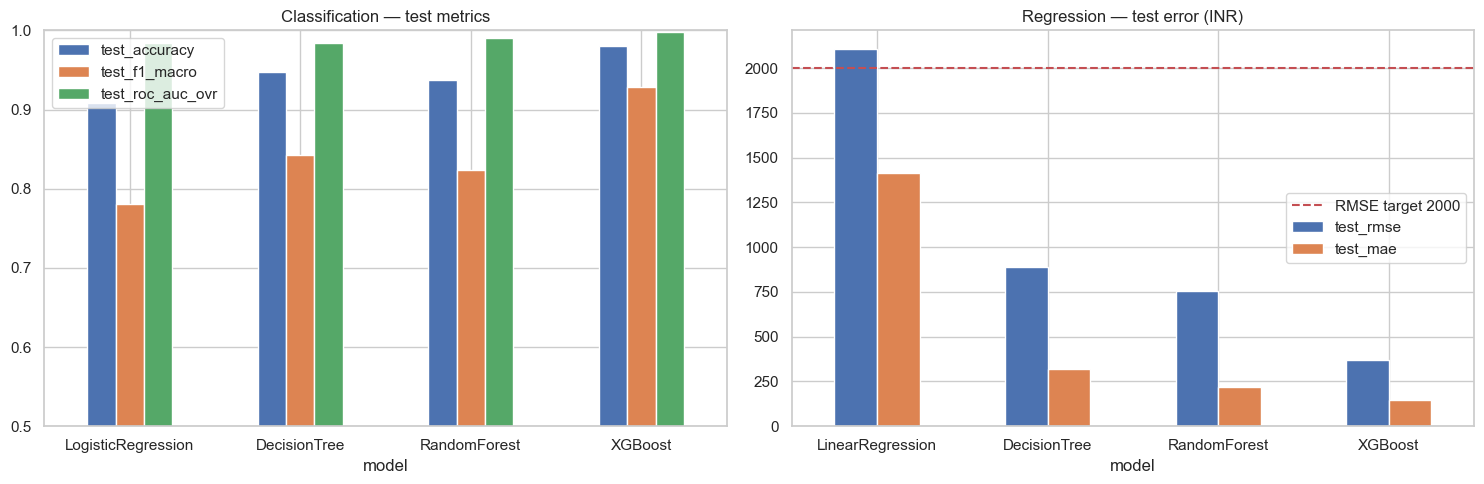

🏆 Best classifier: XGBoost
   val macro-F1 = 0.9306 | test acc = 0.9806 | test AUC = 0.9984
🏆 Best regressor : XGBoost
   val RMSE = 346 | test RMSE = 369 | test R2 = 0.9977

Project targets  ->  accuracy > 90%: ✅ PASS | RMSE < 2000 INR: ✅ PASS


In [21]:
best_clf = clf_df["val_f1_macro"].idxmax()
best_reg = reg_df["val_rmse"].idxmin()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
clf_df[["test_accuracy", "test_f1_macro", "test_roc_auc_ovr"]].plot(kind="bar", ax=ax[0]); ax[0].set_ylim(0.5, 1.0)
ax[0].set_title("Classification — test metrics"); ax[0].tick_params(axis="x", rotation=0)
reg_df[["test_rmse", "test_mae"]].plot(kind="bar", ax=ax[1]); ax[1].axhline(2000, color="r", ls="--", label="RMSE target 2000")
ax[1].set_title("Regression — test error (INR)"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("reports/model_comparison.png", dpi=110); plt.show()

print(f"🏆 Best classifier: {best_clf}\n   val macro-F1 = {clf_df.loc[best_clf,'val_f1_macro']:.4f} | test acc = {clf_df.loc[best_clf,'test_accuracy']:.4f} | test AUC = {clf_df.loc[best_clf,'test_roc_auc_ovr']:.4f}")
print(f"🏆 Best regressor : {best_reg}\n   val RMSE = {reg_df.loc[best_reg,'val_rmse']:.0f} | test RMSE = {reg_df.loc[best_reg,'test_rmse']:.0f} | test R2 = {reg_df.loc[best_reg,'test_r2']:.4f}")

print("\nProject targets  ->  accuracy > 90%:", "✅ PASS" if clf_df.loc[best_clf, "test_accuracy"] > 0.90 else "❌ not met",
      "| RMSE < 2000 INR:", "✅ PASS" if reg_df.loc[best_reg, "test_rmse"] < 2000 else "❌ not met")

In [22]:
# detailed per-class report for the winning classifier
from sklearn.metrics import classification_report
bp = clf_fitted[best_clf].predict(Xte_t)
print(classification_report(yc_te, bp, target_names=eu.CLASS_ORDER, digits=3))

              precision    recall  f1-score   support

    Eligible      0.989     0.971     0.980     10957
   High_Risk      0.714     0.942     0.813      2576
Not_Eligible      0.999     0.985     0.992     45678

    accuracy                          0.981     59211
   macro avg      0.901     0.966     0.928     59211
weighted avg      0.985     0.981     0.982     59211



### Feature importance of the selected models

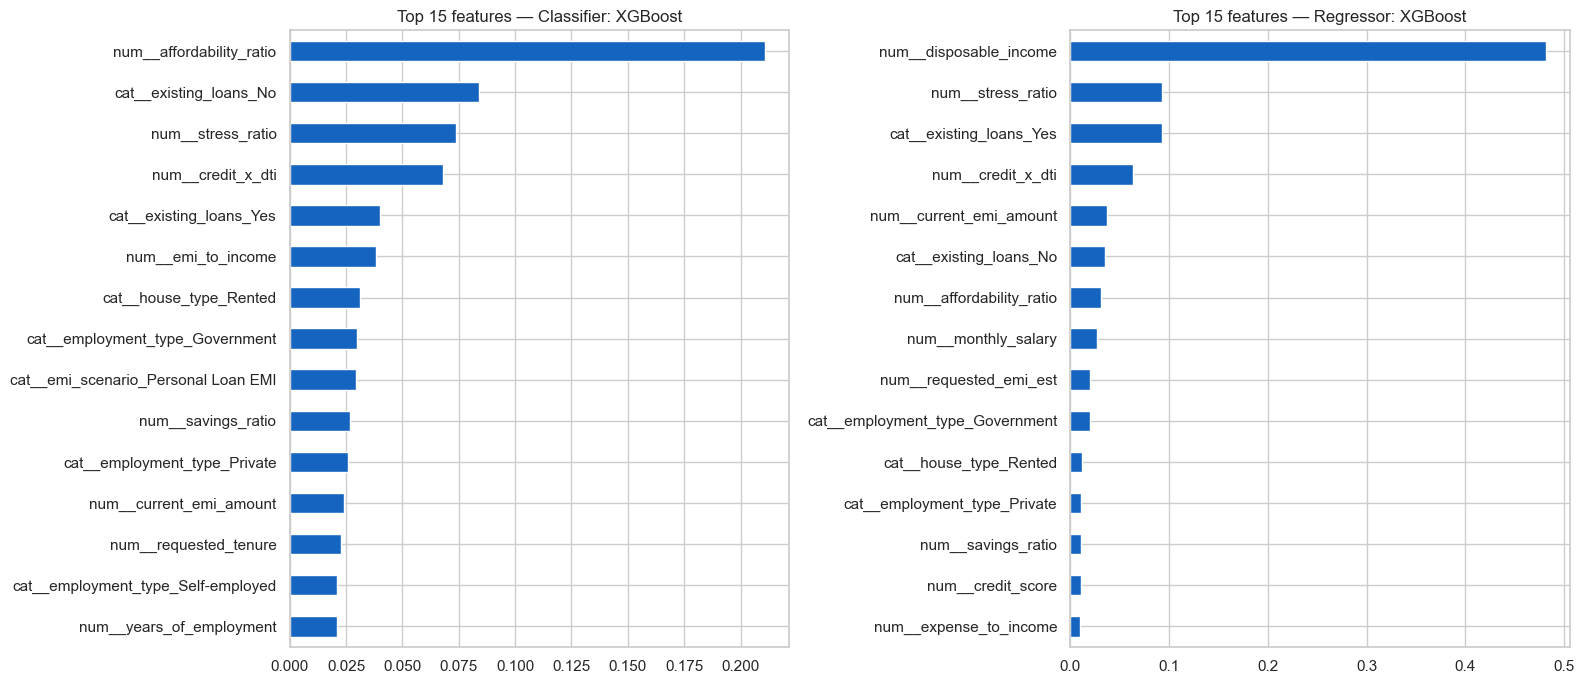

In [23]:
def importances(model):
    if hasattr(model, "feature_importances_"): return np.asarray(model.feature_importances_)
    if hasattr(model, "coef_"): return np.abs(np.asarray(model.coef_)).mean(axis=0) if model.coef_.ndim > 1 else np.abs(model.coef_)
    return None

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, (title, m) in zip(ax, [(f"Classifier: {best_clf}", clf_fitted[best_clf]), (f"Regressor: {best_reg}", reg_fitted[best_reg])]):
    imp = importances(m)
    s = pd.Series(imp, index=feat_names).sort_values().tail(15)
    s.plot(kind="barh", ax=a, color="#1565c0"); a.set_title(f"Top 15 features — {title}")
plt.tight_layout(); plt.savefig("reports/feature_importance.png", dpi=110); plt.show()

## 9. Model registry — promote the winners
Every model variant is a **version** of `EMI_Classifier` / `EMI_Regressor`. The best one gets the alias `champion` (MLflow 3 aliases replace the old Staging/Production stages).

In [24]:
def promote(reg_name, best_name, versions, runs):
    v = versions.get(best_name)
    if v is None:   # fallback for older MLflow: look the version up by run id
        v = next(m.version for m in client.search_model_versions(f"name='{reg_name}'") if m.run_id == runs[best_name])
    client.set_registered_model_alias(reg_name, "champion", str(v))
    client.set_model_version_tag(reg_name, str(v), "selected_because", "best validation metric")
    return v

v_clf = promote(REG_CLF_NAME, best_clf, clf_versions, clf_runs)
v_reg = promote(REG_REG_NAME, best_reg, reg_versions, reg_runs)
print(f"{REG_CLF_NAME}@champion -> v{v_clf} ({best_clf})\n{REG_REG_NAME}@champion -> v{v_reg} ({best_reg})")

# prove the registry round-trip works
champ = mlflow.sklearn.load_model(f"models:/{REG_CLF_NAME}@champion")
print("Registry load OK, sample prediction:", champ.predict(X_te.head(3)))

EMI_Classifier@champion -> v4 (XGBoost)
EMI_Regressor@champion -> v4 (XGBoost)
Registry load OK, sample prediction: [2 2 2]


## 10. Export final models for the Streamlit app

In [25]:
final_clf = Pipeline([("pre", pre), ("model", clf_fitted[best_clf])])
final_reg = Pipeline([("pre", pre), ("model", reg_fitted[best_reg])])
joblib.dump(final_clf, "models/best_classifier.joblib", compress=3)
joblib.dump(final_reg, "models/best_regressor.joblib", compress=3)

def top_feats(m, k=15):
    s = pd.Series(importances(m), index=feat_names).sort_values(ascending=False).head(k)
    return {a: float(b) for a, b in s.items()}

meta = {
    "class_order": eu.CLASS_ORDER, "emi_min": EMI_MIN,
    "best_classifier": best_clf, "best_regressor": best_reg,
    "registry": {"classifier": f"{REG_CLF_NAME}@champion", "regressor": f"{REG_REG_NAME}@champion"},
    "n_rows_used": int(len(df)), "n_train": int(len(X_tr)),
    "classification_results": clf_df.reset_index().to_dict("records"),
    "regression_results": reg_df.reset_index().to_dict("records"),
    "clf_feature_importance": top_feats(clf_fitted[best_clf]),
    "reg_feature_importance": top_feats(reg_fitted[best_reg]),
    "confusion_matrix_test": confusion_matrix(yc_te, bp).tolist(),
    "trained_at": time.strftime("%Y-%m-%d %H:%M"),
}
json.dump(meta, open("models/metadata.json", "w"), indent=2, default=float)
clf_df.to_csv("reports/classification_comparison.csv"); reg_df.to_csv("reports/regression_comparison.csv")

for f in ["best_classifier.joblib", "best_regressor.joblib", "metadata.json"]:
    print(f"models/{f:25s} {os.path.getsize('models/'+f)/1e6:8.1f} MB")

models/best_classifier.joblib         4.4 MB
models/best_regressor.joblib          2.3 MB
models/metadata.json                  0.0 MB


## 11. Smoke test — score one new applicant

In [26]:
applicant = pd.DataFrame([{
    "age": 34, "gender": "Male", "marital_status": "Married", "education": "Graduate",
    "monthly_salary": 85000, "employment_type": "Private", "years_of_employment": 8, "company_type": "MNC",
    "house_type": "Rented", "monthly_rent": 18000, "family_size": 4, "dependents": 2,
    "school_fees": 6000, "college_fees": 0, "travel_expenses": 5000, "groceries_utilities": 14000, "other_monthly_expenses": 8000,
    "existing_loans": "No", "current_emi_amount": 0, "credit_score": 745, "bank_balance": 320000, "emergency_fund": 150000,
    "emi_scenario": "Vehicle EMI", "requested_amount": 600000, "requested_tenure": 48}])

proba = final_clf.predict_proba(applicant)[0]
print("Eligibility :", eu.CLASS_ORDER[int(proba.argmax())], dict(zip(eu.CLASS_ORDER, proba.round(3))))
print("Max EMI     : ₹", int(max(final_reg.predict(applicant)[0], EMI_MIN)))
print("Requested EMI (amount/tenure): ₹", int(600000 / 48))

Eligibility : High_Risk {'Eligible': np.float32(0.002), 'High_Risk': np.float32(0.994), 'Not_Eligible': np.float32(0.004)}
Max EMI     : ₹ 16827
Requested EMI (amount/tenure): ₹ 12500


## 12. Summary / next steps
* Dataset was **dirty** (malformed numerics, 8 gender spellings, out-of-range salary & credit score, ~2.4 K nulls per column) — all handled reproducibly in `emi_utils.clean_data`.
* 4 classifiers + 4 regressors tracked in MLflow; winners registered as `@champion` and exported to `models/`.
* **Run the app:** `streamlit run app.py` · **Open MLflow:** `mlflow ui --backend-store-uri sqlite:///mlflow.db`
* Possible improvements: Optuna tuning of XGBoost, SHAP explanations, probability calibration, SVC on a subsample (SVMs don't scale to 400 K rows).